This notebook contains the following experiment: What would happen to the Kernel's behaviour if we tried to increase one by one the edges, to see how the disimiraity increases

In [1]:
import sys, pathlib
sys.path.append(str(pathlib.Path().resolve().parent))
from src.graph_utils import plot_weighted_graph, compute_Q, ktte,kttw
from src.graph_dataset_preparation import add_uniform_weights, ensure_unique_edge_weights

In [2]:
import networkx as nx

def grid_3x3():
    G = nx.Graph()
    coords = [(i, j) for i in range(3) for j in range(3)]
    G.add_nodes_from(coords)

    for i, j in coords:
        if i < 2:
            G.add_edge((i, j), (i + 1, j))
        if j < 2:
            G.add_edge((i, j), (i, j + 1))
    return G


def prune_isolated(G):
    H = nx.Graph(G)
    isolated = list(nx.isolates(H))
    H.remove_nodes_from(isolated)
    return H


graphs = []

# Graph 1
G = grid_3x3()
graphs.append(prune_isolated(G))

# Progressive edge removals
edge_removals = [
    [((0,0),(1,0))],
    [((0,1),(0,2))],
    [((1,0),(2,0))],
    [((0,0),(0,1))],
    [((2,0),(2,1))],
    [((0,2),(1,2))],
    [((2,2),(2,1))],
    [((2,2),(1,2))],

]

for removal in edge_removals:
    G = nx.Graph(G)
    for e in removal:
        if G.has_edge(*e):
            G.remove_edge(*e)
    G = prune_isolated(G)
    graphs.append(G)



# graphs = [G1, G2, ..., G9]


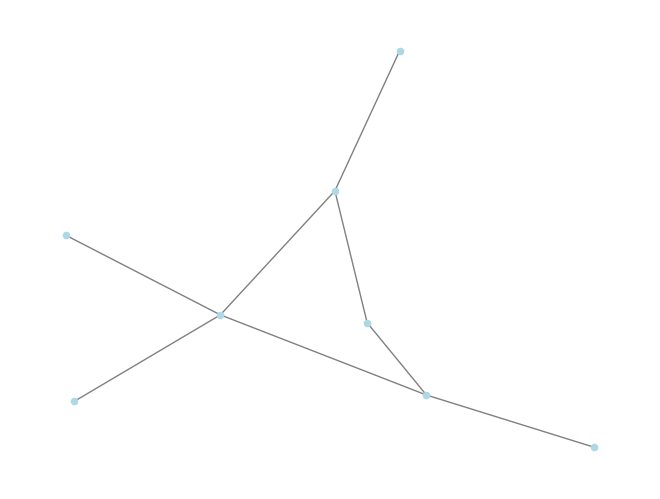

In [3]:
plot_weighted_graph(graphs[4])

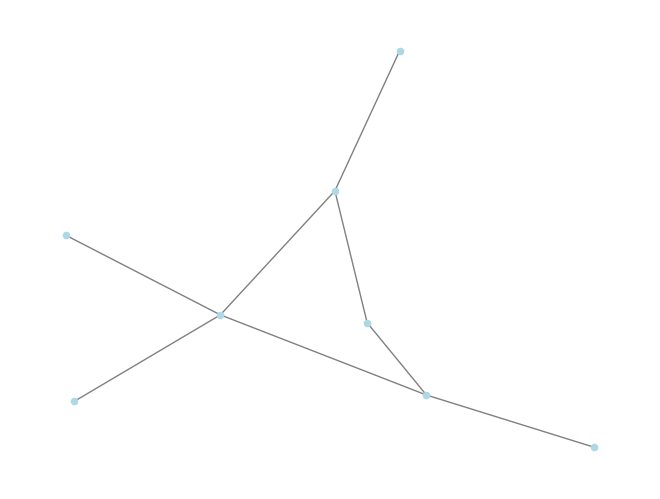

In [5]:
plot_weighted_graph(graphs[4])

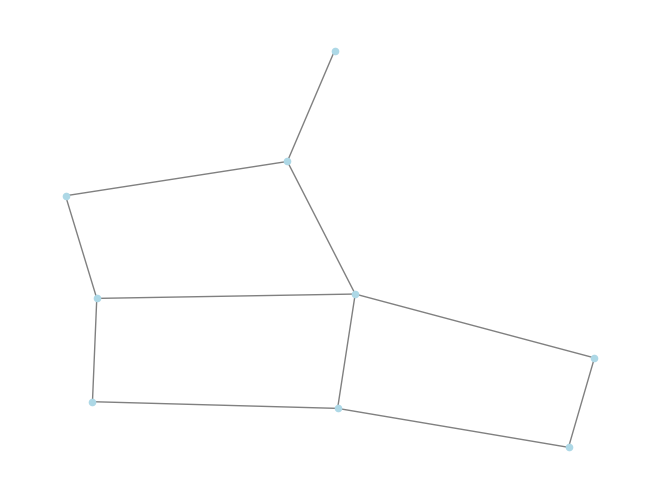

In [8]:
plot_weighted_graph(graphs[1])

In [9]:
type(graphs[0])

networkx.classes.graph.Graph

In [10]:
graphs_w_weights = add_uniform_weights(graphs)
unique_weighted_graphs = ensure_unique_edge_weights(graphs_w_weights)

### Kernel definitions


\begin{aligned}
k_{\mathrm{TTW}}(G_1, G_2)
&=
\exp\!\left(
-\gamma \, W^2\bigl(Q(G_1),\, Q(G_2)\bigr)
\right), \\
\\
k_{\mathrm{TTE}}(G_1, G_2)
&=
\exp\!\left(
-\gamma \, \lVert Q(G_1) - Q(G_2) \rVert_F^2
\right).
\end{aligned}



In [11]:
kts = []
ktws = []
gamma_ = 0.1

while gamma_ <= 1:
    kts_aux = []
    ktws_aux = []
    for i in range(0,len(graphs)):
        Q1 = compute_Q(unique_weighted_graphs[0])
        Q2 = compute_Q(unique_weighted_graphs[i])

        kt = ktte(Q1,Q2, gamma=gamma_)
        ktw = kttw(Q1,Q2, gamma = gamma_)

        kts_aux.append(kt)
        ktws_aux.append(ktw)
    
    kts.append(kts_aux)
    ktws.append(ktws_aux)
    gamma_ += 0.1



Forbenius Product 0.0
Forbenius Product 16.402243641103848
Forbenius Product 16.118747486841244
Forbenius Product 22.478726607993686
Forbenius Product 19.48956277622752
Forbenius Product 20.161593495240744
Forbenius Product 20.59054232539528
Forbenius Product 21.151101111195963
Forbenius Product 21.151101111195963
Forbenius Product 0.0
Forbenius Product 16.402243641103848
Forbenius Product 16.118747486841244
Forbenius Product 22.478726607993686
Forbenius Product 19.48956277622752
Forbenius Product 20.161593495240744
Forbenius Product 20.59054232539528
Forbenius Product 21.151101111195963
Forbenius Product 21.151101111195963
Forbenius Product 0.0
Forbenius Product 16.402243641103848
Forbenius Product 16.118747486841244
Forbenius Product 22.478726607993686
Forbenius Product 19.48956277622752
Forbenius Product 20.161593495240744
Forbenius Product 20.59054232539528
Forbenius Product 21.151101111195963
Forbenius Product 21.151101111195963
Forbenius Product 0.0
Forbenius Product 16.402243641

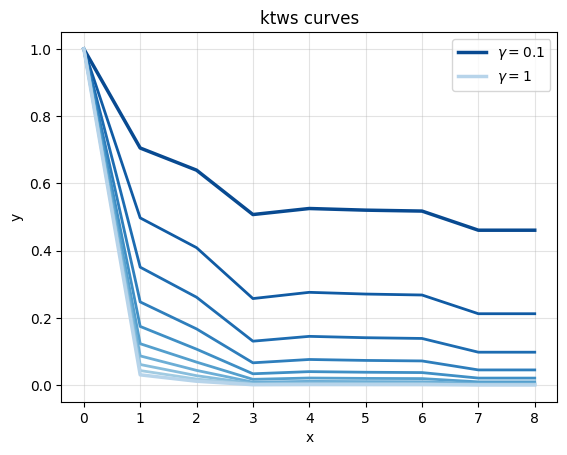

In [12]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 8, 9)

# Dark → light blues
colors = plt.cm.Blues(np.linspace(0.9, 0.3, len(ktws)))

for i, (y, c) in enumerate(zip(ktws, colors)):
    if i == 0:
        plt.plot(x, y, color=c, label=r"$\gamma = 0.1$", linewidth=2.5)
    elif i == len(ktws) - 1:
        plt.plot(x, y, color=c, label=r"$\gamma = 1$", linewidth=2.5)
    else:
        plt.plot(x, y, color=c, linewidth=2)

plt.xlabel("x")
plt.ylabel("y")
plt.title("ktws curves")
plt.grid(True, alpha=0.35)
plt.legend()
plt.show()



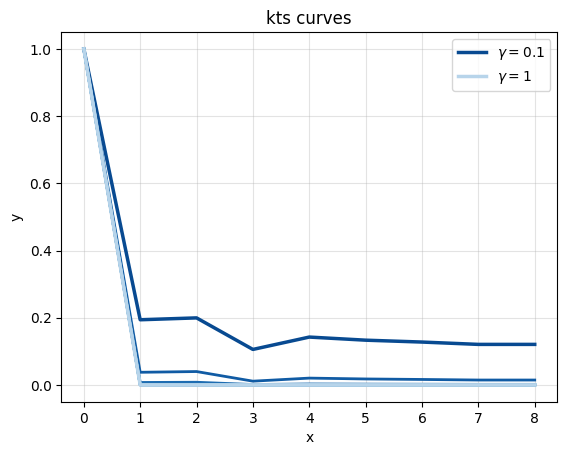

In [13]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 8, 9)

# Dark → light blues
colors = plt.cm.Blues(np.linspace(0.9, 0.3, len(kts)))

for i, (y, c) in enumerate(zip(kts, colors)):
    if i == 0:
        plt.plot(x, y, color=c, label=r"$\gamma = 0.1$", linewidth=2.5)
    elif i == len(kts) - 1:
        plt.plot(x, y, color=c, label=r"$\gamma = 1$", linewidth=2.5)
    else:
        plt.plot(x, y, color=c, linewidth=2)

plt.xlabel("x")
plt.ylabel("y")
plt.title("kts curves")
plt.grid(True, alpha=0.35)
plt.legend()
plt.show()


Experiment: Let's see if I take two distinctly 